# Question 5(c): Monte Carlo verification of ridge excess risk

We use $n=80$, $d=10$, $\Sigma=I_d$, $\theta^*=(1,0,\ldots,0)^\top$, and Gaussian noise $\varepsilon\sim\mathcal N(0,\sigma^2 I_n)$. For each $\sigma\in\{1,3\}$, we generate $M=2000$ independent noise vectors. The design matrix is generated **once**, with a fixed seed, and held fixed throughout the experiment. We evaluate $301$ equally spaced values of $\lambda$ in $[0,3]$.

Because $\Sigma=\Phi^\top\Phi/n=I_d$, the squared fixed-design prediction error is

$$
\frac1n\|\Phi(\widehat\theta_\lambda-\theta^*)\|_2^2
=(\widehat\theta_\lambda-\theta^*)^\top \Sigma(\widehat\theta_\lambda-\theta^*)
=\|\widehat\theta_\lambda-\theta^*\|_2^2.
$$

Thus we can compute the excess error of each fitted estimator directly from its parameter error, without simulating independent fresh labels. From part (b), the analytical expectation and its minimizer are

$$
\mathbb E[R_{\mathrm{fix}}(\widehat\theta_\lambda)]-\sigma^2
=\frac{\lambda^2\|\theta^*\|_2^2+\sigma^2d/n}{(1+\lambda)^2},
\qquad
\lambda^*=\frac{\sigma^2d}{n\|\theta^*\|_2^2}.
$$

In [4]:
import numpy as np
import matplotlib.pyplot as plt

n, d = 80, 10
M = 2000
seed_design, seed_noise = 450, 451
lambda_grid = np.linspace(0.0, 3.0, 301)
theta_star = np.zeros(d)
theta_star[0] = 1.0

# Construct a fixed, reproducible orthonormal-column matrix Q.
rng_design = np.random.default_rng(seed_design)
raw = rng_design.standard_normal((n, d))
Q, R = np.linalg.qr(raw, mode="reduced")
Phi = np.sqrt(n) * Q
Sigma = Phi.T @ Phi / n

print("Maximum entrywise error in Sigma - I_d:",
      np.max(np.abs(Sigma - np.eye(d))))
assert np.allclose(Sigma, np.eye(d), atol=1e-12)
print("Design is fixed across all noise draws and both sigma values.")

Maximum entrywise error in Sigma - I_d: 6.661338147750939e-16
Design is fixed across all noise draws and both sigma values.


For every noise draw, the ridge estimator is

$$
\widehat\theta_\lambda
=\frac1{1+\lambda}\left(\theta^*+\frac{\Phi^\top\varepsilon}{n}\right).
$$

We average the squared errors over the $M$ independent draws for each $\lambda$. We reuse the same $M$ draws across the $\lambda$ grid so that the curves are less noisy; the draws are independent across Monte Carlo repetitions. For each $\sigma$, the theoretical curve is calculated independently from the formula above.

In [5]:
rng_noise = np.random.default_rng(seed_noise)
results = {}

for sigma in (1, 3):
    # M independent N(0, sigma^2 I_n) noise vectors.
    epsilon = rng_noise.normal(loc=0.0, scale=sigma, size=(M, n))
    z = epsilon @ Phi / n             # Phi^T epsilon / n, shape (M, d)

    # Shape (M, number of lambda values, d).
    theta_hat = ((theta_star[None, None, :] + z[:, None, :])
                 / (1.0 + lambda_grid[None, :, None]))
    squared_errors = np.sum((theta_hat - theta_star)**2, axis=-1)
    empirical_risk = squared_errors.mean(axis=0)
    mc_se = squared_errors.std(axis=0, ddof=1) / np.sqrt(M)

    theoretical_risk = ((lambda_grid**2 * np.dot(theta_star, theta_star)
                         + sigma**2 * d / n) / (1.0 + lambda_grid)**2)
    lambda_star = sigma**2 * d / (n * np.dot(theta_star, theta_star))

    results[sigma] = dict(empirical=empirical_risk, theoretical=theoretical_risk,
                          mc_se=mc_se, lambda_star=lambda_star,
                          empirical_minimizer=lambda_grid[np.argmin(empirical_risk)])

    print(f"sigma = {sigma}: theoretical lambda* = {lambda_star:.3f}; "
          f"empirical grid minimizer = {results[sigma]['empirical_minimizer']:.3f}")

sigma = 1: theoretical lambda* = 0.125; empirical grid minimizer = 0.130
sigma = 3: theoretical lambda* = 1.125; empirical grid minimizer = 1.110


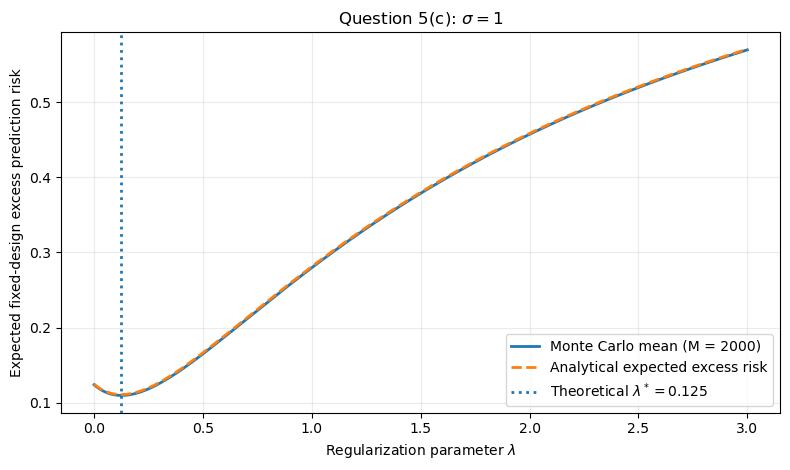

Saved figures/question 5/5c_sigma_1.png. Max |Monte Carlo - analytic|: 0.00147


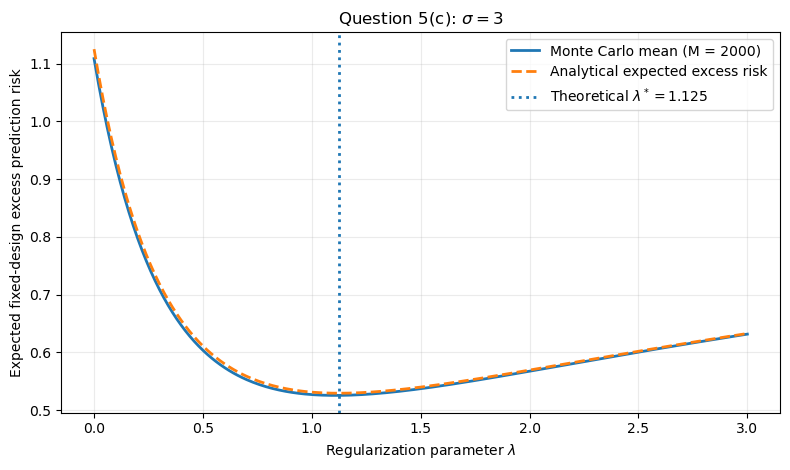

Saved figures/question 5/5c_sigma_3.png. Max |Monte Carlo - analytic|: 0.01639


In [6]:
for sigma, result in results.items():
    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.plot(lambda_grid, result["empirical"], linewidth=2,
            label=f"Monte Carlo mean (M = {M})")
    ax.plot(lambda_grid, result["theoretical"], linestyle="--", linewidth=2,
            label="Analytical expected excess risk")
    ax.axvline(result["lambda_star"], linestyle=":", linewidth=2,
                label=rf"Theoretical $\lambda^*={result['lambda_star']:.3f}$")
    ax.set(xlabel=r"Regularization parameter $\lambda$",
           ylabel="Expected fixed-design excess prediction risk",
           title=rf"Question 5(c): $\sigma={sigma}$")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    filename = f"figures/question 5/5c_sigma_{sigma}.png"
    fig.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved {filename}. Max |Monte Carlo - analytic|: "
          f"{np.max(np.abs(result['empirical'] - result['theoretical'])):.5f}")

The Monte Carlo curves closely follow the analytical risk curves. For $\sigma=1$, the optimal parameter is $\lambda^*=1^2\cdot10/80=0.125$. For $\sigma=3$, it is $\lambda^*=3^2\cdot10/80=1.125$. Therefore, the optimal regularization increases with the noise variance.

This is the bias--variance trade-off derived in part (b). Increasing $\lambda$ reduces estimation variance but introduces squared bias. When $\sigma$ is larger, the variance is larger, so stronger regularization is beneficial. The empirical minimizers may differ slightly from the theoretical ones because the Monte Carlo average uses finitely many noise draws.

The figures are saved as `5c_sigma_1.png` and `5c_sigma_3.png` in `figures/question 5`.